In [87]:
import uproot
import matplotlib.pyplot as plt
import pandas as pd
import tqdm
import numpy as np
import os
import glob
import awkward as ak
import boost_histogram as bh
import mplhep as mh
from matplotlib.colors import LogNorm
import math
mh.style.use("ATLAS")
import particle
# !pip install pyarrow
# !pip install "pyarrow<21" --break-system-packages

In [88]:
events = uproot.open("build/dimuon_presel/merged_all.root:nt", library="ak")

In [90]:
charm_dimuon_events = events[events["truth_isCharmDimuon"] == True]
background_events = events[events["truth_isCharmDimuon"] == False]

print(f"Number of charm dimuon events: {len(charm_dimuon_events)}")

KeyInFileError: not found: 'truth_isCharmDimuon'

    Available keys: 'truth_isDimuon', 'truth_m', 'truth_P', 'truth_pdg', 'truthBarcode', 'truthM_P', 'truthM_x', 'truthM_y', 'truthM_z', 'truth_isFiducial', 'truth_prod_x', 'truth_prod_y', 'truth_prod_z', 'truth_px', 'truth_py'...

in file build/dimuon_presel/merged_all.root
in object /nt;1

ValueError: forward transform of start or stop invalid

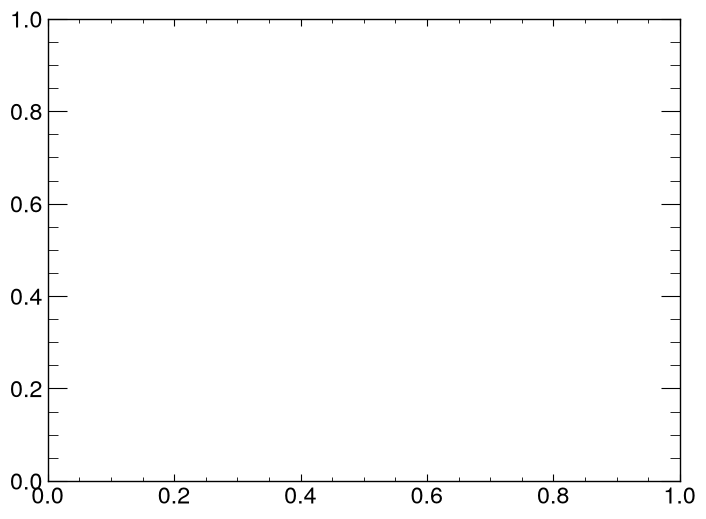

In [ ]:
fig, ax = plt.subplots(figsize=(8, 6))

cm = 1/10
m = 1/1000
units = cm

dca_signal = (charm_dimuon_events["LeadSubLeadTrack_zca_avg"] - 3100) * units
dca_background = (background_events["LeadSubLeadTrack_zca_avg"] - 3100) * units

min_dca = min(np.min(dca_signal), np.min(dca_background))
max_dca = max(np.max(dca_signal), np.max(dca_background))

nbins = 5000

h_dca_signal = bh.Histogram(bh.axis.Regular(nbins, min_dca, max_dca), storage=bh.storage.Weight())
h_dca_background = bh.Histogram(bh.axis.Regular(nbins, min_dca, max_dca), storage=bh.storage.Weight())

h_dca_signal.fill(dca_signal)
h_dca_background.fill(dca_background)

bkg_scale =  len(background_events) / len(charm_dimuon_events)

mh.histplot([h_dca_background, h_dca_signal], ax=ax, label=[ "Background", "Signal (Dimuon)"], color=["orange", "blue"], histtype="fill", stack=True)
mh.histplot(h_dca_signal * bkg_scale, ax=ax, label="Signal (Dimuon)", color="blue", histtype="step", linewidth=1, linestyle="--")

# ax.axvline(x=-136*units -1950*units, color="black", linestyle="--", label="Cut threshold (Category A)", linewidth=1)
# ax.axvline(x=-340*units -1950*units, color="grey", linestyle="--", label="Cut threshold (Category B)", linewidth=1)
ax.axvline(x=-333*units -1950*units, color="black", linestyle="--", label="Cut threshold (Category A)", linewidth=1)


faser_box_start_stop = (-3000*units, -1950*units)
ax.fill_betweenx([1e-3, 1e6], faser_box_start_stop[0], faser_box_start_stop[1], color="darkgrey", alpha=0.3, label="FASERNu Box")

lead_block_start_stop = (-1769.65*units, -1619.65*units)
ax.fill_betweenx([1e-3, 1e6], lead_block_start_stop[0], lead_block_start_stop[1], color="grey", alpha=0.3, label="Lead Block")

ax.set_ylim(1e-3, 0.4e4)
ax.set_xlim(-4000*units, 1000*units)
# ax.set_yscale("log")
ax.set_xscale("linear")
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
ax.set_xlabel(r"$z_{ca}$ [cm]")

ValueError: forward transform of start or stop invalid

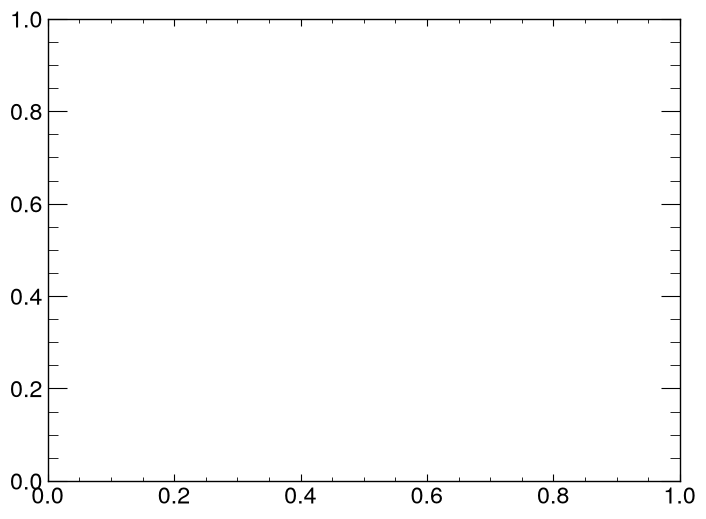

In [ ]:
fig, ax = plt.subplots(figsize=(8, 6))

dca_signal = charm_dimuon_events["LeadSubLeadTrack_zca_abs"]
dca_background = background_events["LeadSubLeadTrack_zca_abs"]

max_dca = max(np.max(dca_signal), np.max(dca_background))
min_dca = min(np.min(dca_signal), np.min(dca_background))

h_dca_signal = bh.Histogram(bh.axis.Regular(100, min_dca, max_dca), storage=bh.storage.Weight())
h_dca_background = bh.Histogram(bh.axis.Regular(100, min_dca, max_dca), storage=bh.storage.Weight())

h_dca_signal.fill(dca_signal)
h_dca_background.fill(dca_background)

ax.set_xlim(0,1 )

bkg_scale =  len(background_events) / len(charm_dimuon_events)  

mh.histplot([h_dca_background, h_dca_signal], ax=ax, label=[ "Background", "Signal (Dimuon)"], color=["orange", "blue"], histtype="fill", stack=True)
mh.histplot(h_dca_signal * bkg_scale, ax=ax, label="Signal (Dimuon)", color="blue", histtype="step", linewidth=2)


ax.set_yscale("log")
ax.legend()

ValueError: forward transform of start or stop invalid

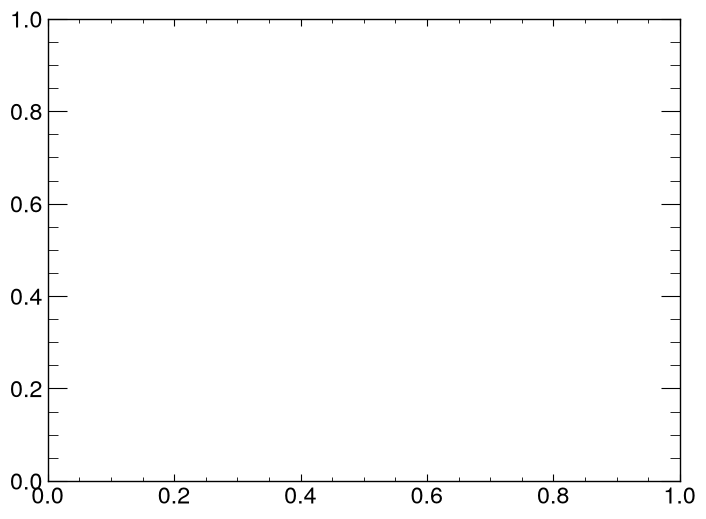

In [ ]:
fig, ax = plt.subplots(figsize=(8, 6))

dca_signal = charm_dimuon_events["LeadSubLeadTrack_distance"]
dca_background = background_events["LeadSubLeadTrack_distance"]

min_dca = min(np.min(dca_signal), np.min(dca_background))
max_dca = max(np.max(dca_signal), np.max(dca_background))



h_dca_signal = bh.Histogram(bh.axis.Regular(100, min_dca, max_dca), storage=bh.storage.Weight())
h_dca_background = bh.Histogram(bh.axis.Regular(100, min_dca, max_dca), storage=bh.storage.Weight())

h_dca_signal.fill(dca_signal)
h_dca_background.fill(dca_background)

bkg_scale =  len(background_events) / len(charm_dimuon_events)

mh.histplot([h_dca_background, h_dca_signal], ax=ax, label=[ "Background", "Signal (Dimuon)"], color=["orange", "blue"], histtype="fill", stack=True)
mh.histplot(h_dca_signal * bkg_scale, ax=ax, label="Signal (Dimuon)", color="blue", histtype="step", linewidth=2)

ax.set_xlim(0, 100)
ax.set_yscale("log")
ax.legend()

In [ ]:
fig, ax = plt.subplots(figsize=(8, 6))

# for x in charm_dimuon_events.fields:
#     print(x)

dca_signal = charm_dimuon_events["Calo_total_E_EM"] / 1e3
dca_background = background_events["Calo_total_E_EM"] / 1e3

min_dca = min(np.min(dca_signal), np.min(dca_background))
max_dca = max(np.max(dca_signal), np.max(dca_background))

if min_dca < 0:
    min_dca = 0

h_dca_signal = bh.Histogram(bh.axis.Regular(5000, min_dca, max_dca), storage=bh.storage.Weight())
h_dca_background = bh.Histogram(bh.axis.Regular(5000, min_dca, max_dca), storage=bh.storage.Weight())

h_dca_signal.fill(dca_signal)
h_dca_background.fill(dca_background)

bkg_scale =  len(background_events) / len(charm_dimuon_events)

mh.histplot([h_dca_background, h_dca_signal], ax=ax, label=[ "Background", "Signal (Dimuon)"], color=["orange", "blue"], histtype="fill", stack=True)
mh.histplot(h_dca_signal * bkg_scale, ax=ax, label="Signal (Dimuon)", color="blue", histtype="step", linewidth=2)

ax.axvline(x=1.4, color="black", linestyle="--", label="Cut threshold", linewidth=1)

ax.set_xlim(0, 30)
# ax.set_yscale("log")
ax.legend()
ax.set_xlabel(r"$E_{EM}$ [GeV]")

In [ ]:
# fig, ax = plt.subplots(figsize=(8, 6))

# for x in charm_dimuon_events.fields:
#     print(x)

dca_signal = charm_dimuon_events["Calo_total_E_EM"] / 1e3
dca_background = background_events["Calo_total_E_EM"] / 1e3

min_dca = min(np.min(dca_signal), np.min(dca_background))
max_dca = max(np.max(dca_signal), np.max(dca_background))

if min_dca < 0:
    min_dca = 0

h_dca_signal = bh.Histogram(bh.axis.Regular(5000, min_dca, max_dca), storage=bh.storage.Weight())
h_dca_background = bh.Histogram(bh.axis.Regular(5000, min_dca, max_dca), storage=bh.storage.Weight())

h_dca_signal.fill(dca_signal)
h_dca_background.fill(dca_background)

bkg_scale =  len(background_events) / len(charm_dimuon_events)

fig, ax_main, ax_comp = mh.comp.hists(
 h_dca_signal,
 h_dca_background,
 comparison='ratio',
 xlabel=r"$E_{EM}$ [GeV]",
 ylabel='Events',
 h1_label='Signal (Dimuon)',
 h2_label='Background'
)

# mh.histplot(h_dca_signal * bkg_scale, ax=ax, label="Signal (Dimuon)", color="blue", histtype="step", linewidth=2)

# ax.axvline(x=1.4, color="black", linestyle="--", label="Cut threshold", linewidth=1)
ax_main.axvline(x=11, color="black", linestyle="--", label="Cut threshold", linewidth=1)
ax_comp.axvline(x=11, color="black", linestyle="--", label="Cut threshold", linewidth=1)

ax_main.set_xlim(0, 100)
ax_comp.set_xlim(0, 100)


# ax.set_xlim(0, 30)
# ax.set_yscale("log")
# ax.legend()
# ax.set_xlabel(r"$E_{EM}$ [GeV]")

In [ ]:
cm = 1/10
m = 1/1000
units = cm

dca_signal = (charm_dimuon_events["LeadSubLeadTrack_zca_avg"] - 3100) * units
dca_background = (background_events["LeadSubLeadTrack_zca_avg"] - 3100) * units

min_dca = min(np.min(dca_signal), np.min(dca_background))
max_dca = max(np.max(dca_signal), np.max(dca_background))

nbins = 5000

h_dca_signal = bh.Histogram(bh.axis.Regular(nbins, min_dca, max_dca), storage=bh.storage.Weight())
h_dca_background = bh.Histogram(bh.axis.Regular(nbins, min_dca, max_dca), storage=bh.storage.Weight())

h_dca_signal.fill(dca_signal)
h_dca_background.fill(dca_background)

bkg_scale =  len(background_events) / len(charm_dimuon_events)

fig, ax_main, ax_comp = mh.comp.hists(
 h_dca_signal,
 h_dca_background,
 comparison='ratio',
 xlabel=r"$z_{ca}$ [cm]",
 ylabel='Events',
 h1_label='Signal (Dimuon)',
 h2_label='Background'
)

# ax.axvline(x=-136*units -1950*units, color="black", linestyle="--", label="Cut threshold (Category A)", linewidth=1)
# ax.axvline(x=-340*units -1950*units, color="grey", linestyle="--", label="Cut threshold (Category B)", linewidth=1)
ax_main.axvline(x=-333*units -1950*units, color="black", linestyle="--", label="Cut threshold", linewidth=1)
# ax_comp.axvline(x=-333*units -1950*units, color="black", linestyle="--", label="Cut threshold", linewidth=1)


faser_box_start_stop = (-3000*units, -1950*units)
ax_main.fill_betweenx([1e-3, 1e6], faser_box_start_stop[0], faser_box_start_stop[1], color="darkgrey", alpha=0.3, label="FASERNu Box")
ax_comp.fill_betweenx([0, 2], faser_box_start_stop[0], faser_box_start_stop[1], color="darkgrey", alpha=0.3, label="FASERNu Box")

lead_block_start_stop = (-1769.65*units, -1619.65*units)
ax_main.fill_betweenx([1e-3, 1e6], lead_block_start_stop[0], lead_block_start_stop[1], color="grey", alpha=0.3, label="Lead Block")
ax_comp.fill_betweenx([0, 2], lead_block_start_stop[0], lead_block_start_stop[1], color="grey", alpha=0.3, label="Lead Block")

ax_main.set_ylim(1e-3, 0.4e4)

ax_main.set_xlim(-4000*units, 1000*units)
ax_comp.set_xlim(-4000*units, 1000*units)
# ax.set_yscale("log")
ax_main.set_xscale("linear")
ax_main.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
ax_main.set_xlabel(r"$z_{ca}$ [cm]")

In [ ]:
dca_signal = charm_dimuon_events["longTracks"] 
dca_background = background_events["longTracks"]

min_dca = min(np.min(dca_signal), np.min(dca_background))
max_dca = max(np.max(dca_signal), np.max(dca_background))

nbins = 10

h_dca_signal = bh.Histogram(bh.axis.Regular(nbins, 0, 10), storage=bh.storage.Weight())
h_dca_background = bh.Histogram(bh.axis.Regular(nbins, 0, 10), storage=bh.storage.Weight())

h_dca_signal.fill(dca_signal)
h_dca_background.fill(dca_background)

bkg_scale =  len(background_events) / len(charm_dimuon_events)

fig, ax_main, ax_comp = mh.comp.hists(
 h_dca_signal,
 h_dca_background,
 comparison='ratio',
 xlabel=r"n long tracks",
 ylabel='Events',
 h1_label='Signal (Dimuon)',
 h2_label='Background'
)

ax_main.axvline(x=4, color="black", linestyle="--", label="Cut threshold", linewidth=1)
ax_main.axvline(x=2, color="black", linestyle="--", label="Cut threshold", linewidth=1)

ax_main.set_xscale("linear")
ax_main.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
ax_main.set_xlabel(r"$z_{ca}$ [cm]")

In [ ]:
# fig, ax = plt.subplots(figsize=(8, 6))

# for x in charm_dimuon_events.fields:
#     print(x)

dca_signal = charm_dimuon_events["Preshower0_charge"]
dca_background = background_events["Preshower0_charge"]

min_dca = min(np.min(dca_signal), np.min(dca_background))
max_dca = max(np.max(dca_signal), np.max(dca_background))

if min_dca < 0:
    min_dca = 0

h_dca_signal = bh.Histogram(bh.axis.Regular(5000, min_dca, max_dca), storage=bh.storage.Weight())
h_dca_background = bh.Histogram(bh.axis.Regular(5000, min_dca, max_dca), storage=bh.storage.Weight())

h_dca_signal.fill(dca_signal)
h_dca_background.fill(dca_background)

bkg_scale =  len(background_events) / len(charm_dimuon_events)

fig, ax_main, ax_comp = mh.comp.hists(
 h_dca_signal,
 h_dca_background,
 comparison='ratio',
 xlabel=r"Preshower0 charge [pC]",
 ylabel='Events',
 h1_label='Signal (Dimuon)',
 h2_label='Background'
)

# mh.histplot(h_dca_signal * bkg_scale, ax=ax, label="Signal (Dimuon)", color="blue", histtype="step", linewidth=2)

# ax.axvline(x=1.4, color="black", linestyle="--", label="Cut threshold", linewidth=1)
# ax_main.axvline(x=11, color="black", linestyle="--", label="Cut threshold", linewidth=1)
# ax_comp.axvline(x=11, color="black", linestyle="--", label="Cut threshold", linewidth=1)

ax_main.set_xlim(0, 100)
ax_comp.set_xlim(0, 100)


# ax.set_xlim(0, 30)
# ax.set_yscale("log")
# ax.legend()
# ax.set_xlabel(r"$E_{EM}$ [GeV]")

In [ ]:
d